# AdaBoost: German Credit
DSE4212/QF4212 Group Project 1

Convention used everywhere: **positive class (1) = default / bad credit**.
Same split, preprocessing pipeline, CV scheme, threshold rules and `evaluate()` as the logistic
regression and random forest notebooks.

- Part 1: Method and untuned reference model
- Part 2: Hyperparameter tuning (cross-validation on training data only)
- Part 3: Operating points (thresholds from out-of-fold predictions)
- Part 4: Test-set evaluation
- Part 5: Interpretation (permutation importance)
- Part 6: Save model, probabilities and metrics

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import joblib

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

# Find the project root (the folder that contains src/) so `from src...` works
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing import make_pipeline, check_inputs   # shared preprocessing
from src.evaluation import (evaluate, metrics_only, results_table,
                            f1_optimal_threshold, cost_min_threshold,
                            cost_optimal_threshold, bootstrap_auc_ci, RANDOM_STATE)

matplotlib.rcParams.update({'font.size': 12})

# Output folders
OUT = ROOT / "outputs"
for sub in ("models", "predictions", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# Settings (identical to the logistic regression notebook)
TARGET = "credit_risk"   # 1 = default (bad), 0 = good
FN_COST = 5              # a missed default costs 5x a wrongly rejected good client

## Load data
The team's fixed `train.csv` / `test.csv` split (800 / 200 rows, stratified, seed 4212), so this model is trained and tested on exactly the same rows as logistic regression.

In [2]:
train = pd.read_csv(OUT / "train.csv")
test = pd.read_csv(OUT / "test.csv")

y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])

print("train:", X_train.shape, "| test:", X_test.shape)
print(f"Default rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
check_inputs(X_train)   # raises if expected columns are missing

train: (800, 26) | test: (200, 26)
Default rate: train 0.300, test 0.300


## Part 1: Method and untuned reference model
**AdaBoost (SAMME).** Fits a *sequence* of small trees. After each round, the rows the ensemble
misclassifies get more weight, so the next tree focuses on them. The final score is a weighted
vote of all trees. Where a random forest averages deep trees to reduce variance, boosting adds
shallow trees to reduce bias. The learning rate shrinks each tree's vote and trades off against
the number of rounds.

**Preprocessing.** The shared `make_pipeline` with `scale_numeric=False` (trees do not need scaling).
Sensitive attributes are not model inputs.

**Class imbalance (30% defaults)** is handled at two levels:
1. *Training:* `class_weight="balanced"` on the base tree upweights defaults ~2.3× inside every
   boosting round. It is tuned against `None`.
2. *Decision:* the cost-optimal threshold from out-of-fold predictions (Part 3). This matters more
   for AdaBoost than for the other models. Its `predict_proba` is a softmax of the weighted vote, and
   these probabilities are **squeezed towards 0.5** and not calibrated, so 0.5 is not a meaningful
   cut-off and the 1/(1+5) ≈ 0.167 rule from calibrated-probability theory does not apply.

The reference model is scikit-learn's default: 50 decision stumps (depth 1), learning rate 1.

In [3]:
ada_default = make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE), scale_numeric=False)
ada_default.fit(X_train, y_train)
res_default = evaluate(ada_default, X_test, y_test, name="AdaBoost untuned (50 stumps, lr=1)",
                       fn_cost=FN_COST)

=== AdaBoost untuned (50 stumps, lr=1) | threshold = 0.500 ===
AUC 0.8042 | Precision 0.6818 | Recall 0.5000 | F1 0.5769 | Accuracy 0.7800
          pred 0  pred 1
actual 0     126      14
actual 1      30      30


## Part 2: Hyperparameter tuning (training data only)
`RepeatedStratifiedKFold` (5 folds × 2 repeats, seed 4212), scored on ROC AUC, as for the other models.

| Parameter | Values | Role |
|---|---|---|
| `n_estimators` | 100, 300, 600 | boosting rounds |
| `learning_rate` | 0.03, 0.1, 0.3, 1.0 | shrinkage of each tree's vote |
| `estimator__max_depth` | 1, 2, 3 | base-tree depth (1 = stumps, additive model; 2-3 = pairwise/three-way interactions) |
| `estimator__class_weight` | None, balanced | class-imbalance reweighting |

72 combinations × 10 fits = 720 ensembles. Because boosting fits the training data more and more
closely with each round, the train-fold AUC is also recorded to check for overfitting.

In [4]:
base = make_pipeline(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                       random_state=RANDOM_STATE),
    scale_numeric=False,
)
param_grid = {
    "classifier__n_estimators": [100, 300, 600],
    "classifier__learning_rate": [0.03, 0.1, 0.3, 1.0],
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__class_weight": [None, "balanced"],
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
gs = GridSearchCV(base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True,
                  return_train_score=True)

t0 = time.time()
gs.fit(X_train, y_train)
print(f"Grid search took {time.time() - t0:.0f}s")

best = gs.best_estimator_
cvr = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cv_std = cvr.iloc[0]["std_test_score"]
cv_train = cvr.iloc[0]["mean_train_score"]

print(f"Best params: {gs.best_params_}")
print(f"CV AUC: {gs.best_score_:.4f} (+/- {cv_std:.4f}) | mean train-fold AUC {cv_train:.4f}")
cols = ["param_classifier__n_estimators", "param_classifier__learning_rate",
        "param_classifier__estimator__max_depth", "param_classifier__estimator__class_weight",
        "mean_test_score", "std_test_score", "mean_train_score"]
cvr[cols].head(10)

Grid search took 46s
Best params: {'classifier__estimator__class_weight': None, 'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 0.3, 'classifier__n_estimators': 300}
CV AUC: 0.7682 (+/- 0.0274) | mean train-fold AUC 0.9088


,param_classifier__n_estimators,param_classifier__learning_rate,param_classifier__estimator__max_depth,param_classifier__estimator__class_weight,mean_test_score,std_test_score,mean_train_score
19,300,0.3,2,None,0.768211,0.027426,0.908811
20,600,0.3,2,None,0.766034,0.029381,0.927723
30,100,0.3,3,None,0.765067,0.040125,0.933919
21,100,1.0,2,None,0.764435,0.034819,0.945358
18,100,0.3,2,None,0.762733,0.022613,0.885161
17,600,0.1,2,None,0.760733,0.028033,0.892225
31,300,0.3,3,None,0.760621,0.036557,0.964215
32,600,0.3,3,None,0.759431,0.034616,0.988554
16,300,0.1,2,None,0.759115,0.026767,0.878127
28,300,0.1,3,None,0.757673,0.033202,0.923404


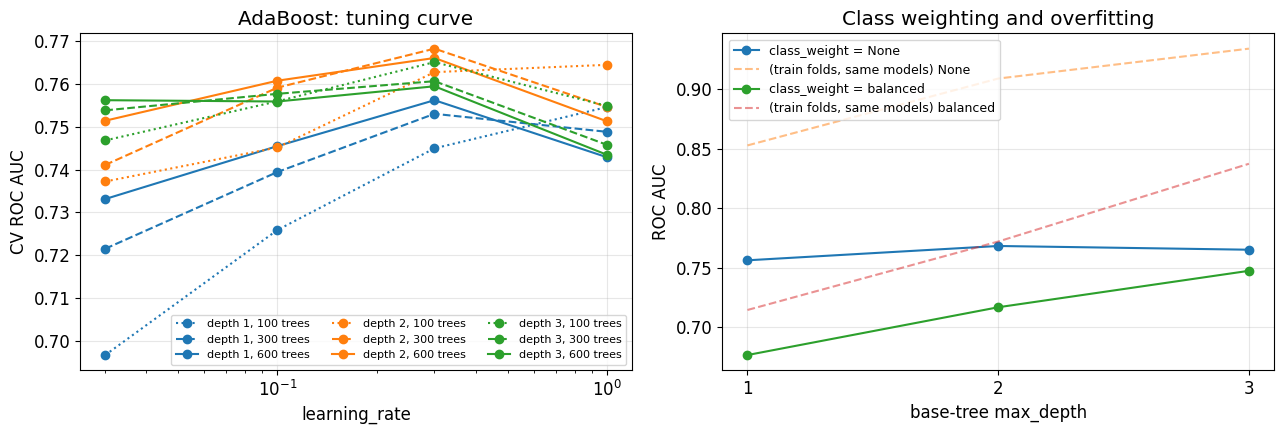

,best CV AUC,mean CV AUC over grid
weight,,
None,0.768211,0.749447
balanced,0.747359,0.705386


In [5]:
# CV AUC vs learning rate for each depth (best over the other parameters), and class weighting
cvr["weight"] = cvr["param_classifier__estimator__class_weight"].apply(lambda w: "balanced" if w == "balanced" else "None")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for depth, g in cvr.groupby("param_classifier__estimator__max_depth"):
    for n, gg in g.groupby("param_classifier__n_estimators"):
        s = gg.groupby("param_classifier__learning_rate")["mean_test_score"].max()
        axes[0].plot(s.index.astype(float), s.values, marker="o",
                     ls={100: ":", 300: "--", 600: "-"}[int(n)],
                     color={1: "C0", 2: "C1", 3: "C2"}[int(depth)],
                     label=f"depth {depth}, {n} trees")
axes[0].set_xscale("log")
axes[0].set(xlabel="learning_rate", ylabel="CV ROC AUC", title="AdaBoost: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, ncol=3)

for w, g in cvr.groupby("weight"):
    s = g.groupby("param_classifier__estimator__max_depth")["mean_test_score"].max()
    axes[1].plot(s.index.astype(int), s.values, marker="o", label=f"class_weight = {w}")
    s_tr = g.loc[g.groupby("param_classifier__estimator__max_depth")["mean_test_score"].idxmax()]
    axes[1].plot(s_tr["param_classifier__estimator__max_depth"].astype(int), s_tr["mean_train_score"],
                 ls="--", alpha=0.5, label=f"(train folds, same models) {w}")
axes[1].set_xticks([1, 2, 3])
axes[1].set(xlabel="base-tree max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/adaboost_tuning_curve.png", dpi=200)
plt.show()

cvr.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best AdaBoost uses depth-2 trees, learning rate 0.3, 300 rounds and **no class
weighting** (CV AUC 0.768 ± 0.027, train-fold AUC 0.909). Depth-2 trees beat stumps at almost every learning rate.
This suggests pairwise interactions carry signal, as the engineered interaction flags already hinted.
A learning rate of 1.0 overfits, and 0.03 would need more rounds than the grid allows.

**Class weighting clearly hurts AdaBoost** (best CV AUC 0.747 vs 0.768; mean over the grid 0.705 vs 0.749).
Boosting already reweights the rows it gets wrong, and those are disproportionately defaults.
Adding a fixed 2.3× class weight on top over-emphasises the minority class and makes the ensemble noisier.
For AdaBoost, imbalance is therefore handled only at the decision threshold.

## Part 3: Operating points (thresholds)
As for logistic regression, the threshold is chosen from **out-of-fold training predictions** (5-fold stratified CV of the tuned pipeline), never from the test set:

- 0.5, the default
- the F1-optimal threshold
- the cost-optimal threshold, minimising `FN_COST`·FN + FP on the training folds

In [6]:
oof = cross_val_predict(best, X_train, y_train, method="predict_proba",
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))[:, 1]
pd.DataFrame({"index": X_train.index, "y_true": y_train.values, "y_proba": oof}).to_csv(
    OUT / "predictions/adaboost_train_oof_proba.csv", index=False)

t_f1 = f1_optimal_threshold(y_train, oof)
t_cost = cost_min_threshold(y_train, oof, cost_fn=FN_COST)
print(f"F1-optimal threshold: {t_f1:.3f} | cost-optimal threshold (FN:FP = {FN_COST}:1): {t_cost:.3f} "
      f"(theory for perfectly calibrated probabilities: {cost_optimal_threshold(FN_COST):.3f})")

F1-optimal threshold: 0.457 | cost-optimal threshold (FN:FP = 5:1): 0.364 (theory for perfectly calibrated probabilities: 0.167)


## Part 4: Test-set evaluation
The test set is used once, here. Test-set probabilities are saved to `outputs/predictions/adaboost_test_proba.csv` (same format as `logreg_test_proba.csv`).

In [7]:
res_05 = evaluate(best, X_test, y_test, threshold=0.5, name="AdaBoost tuned @ 0.5", fn_cost=FN_COST,
                  save_to=str(OUT / "predictions/adaboost_test_proba.csv"))
res_f1 = evaluate(best, X_test, y_test, threshold=t_f1, name="AdaBoost tuned @ F1-optimal", fn_cost=FN_COST)
res_cost = evaluate(best, X_test, y_test, threshold=t_cost, name="AdaBoost tuned @ cost-optimal", fn_cost=FN_COST)

ci = bootstrap_auc_ci(y_test, res_05["y_proba"])
print(f"\nTest AUC = {res_05['auc']:.3f}, 95% bootstrap CI [{ci[0]:.3f}, {ci[1]:.3f}]")

=== AdaBoost tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8176 | Precision 0.7500 | Recall 0.5000 | F1 0.6000 | Accuracy 0.8000
          pred 0  pred 1
actual 0     130      10
actual 1      30      30
=== AdaBoost tuned @ F1-optimal | threshold = 0.457 ===
AUC 0.8176 | Precision 0.5714 | Recall 0.6667 | F1 0.6154 | Accuracy 0.7500
          pred 0  pred 1
actual 0     110      30
actual 1      20      40
=== AdaBoost tuned @ cost-optimal | threshold = 0.364 ===
AUC 0.8176 | Precision 0.3972 | Recall 0.9333 | F1 0.5572 | Accuracy 0.5550
          pred 0  pred 1
actual 0      55      85
actual 1       4      56



Test AUC = 0.818, 95% bootstrap CI [0.748, 0.880]


In [8]:
table = results_table([res_default, res_05, res_f1, res_cost], fn_cost=FN_COST)
table.to_csv(OUT / "results/adaboost_results_table.csv", index=False)
table

,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,"AdaBoost untuned (50 stumps, lr=1)",0.500,0.804,0.682,0.500,0.577,0.780,126/14/30/30,164.0
1,AdaBoost tuned @ 0.5,0.500,0.818,0.750,0.500,0.600,0.800,130/10/30/30,160.0
2,AdaBoost tuned @ F1-optimal,0.457,0.818,0.571,0.667,0.615,0.750,110/30/20/40,130.0
3,AdaBoost tuned @ cost-optimal,0.364,0.818,0.397,0.933,0.557,0.555,55/85/4/56,105.0


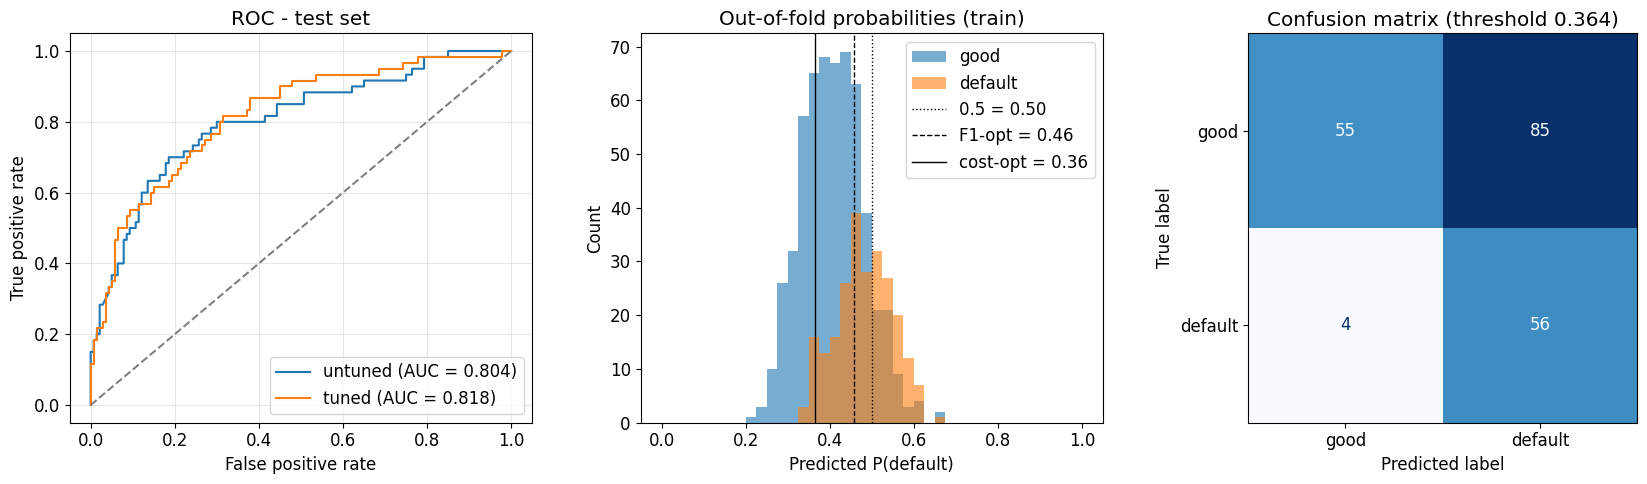

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ROC curves on the test set
for res, lab in [(res_default, "untuned"), (res_05, "tuned")]:
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0].plot(fpr, tpr, label=f"{lab} (AUC = {res['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

# Distribution of predicted probabilities (out-of-fold, training set)
bins = np.linspace(0, 1, 41)
axes[1].hist(oof[y_train == 0], bins=bins, alpha=0.6, label="good")
axes[1].hist(oof[y_train == 1], bins=bins, alpha=0.6, label="default")
for t, ls, lab in [(0.5, ":", "0.5"), (t_f1, "--", "F1-opt"), (t_cost, "-", "cost-opt")]:
    axes[1].axvline(t, color="k", ls=ls, lw=1, label=f"{lab} = {t:.2f}")
axes[1].set(xlabel="Predicted P(default)", ylabel="Count", title="Out-of-fold probabilities (train)")
axes[1].legend()

# Confusion matrix at the cost-optimal threshold
ConfusionMatrixDisplay(res_cost["confusion_matrix"], display_labels=["good", "default"]).plot(
    ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title(f"Confusion matrix (threshold {t_cost:.3f})")

plt.tight_layout()
plt.savefig(OUT / "results/adaboost_roc_confusion.png", dpi=200)
plt.show()

**Remark.** Test AUC is 0.818 (95% CI 0.748–0.880), the highest of the three models on the test set,
even though AdaBoost had the *lowest* CV AUC. The two estimates disagree by more than the gap between models.
This is another sign that the models cannot be separated on these data (see `model_comparison.ipynb`).

The histogram shows the squeezed probabilities: every out-of-fold prediction lies between ≈ 0.2 and 0.67.
Thresholds must therefore be learned from the data. The cost-optimal threshold is 0.364, compared with 0.167 for calibrated
probabilities. At this threshold AdaBoost catches **56 of 60 defaulters (recall 0.93)** but rejects 85 of 140 good
clients, for a cost of **105**, down from 160 at 0.5.

## Part 5: Interpretation (permutation importance)
Tree ensembles have no coefficients. **Permutation importance** measures how much the test AUC drops when one *original* input column is shuffled (20 repeats). Shuffling a raw column also breaks every one-hot dummy and engineered flag built from it, so the importance of a categorical variable is reported once, not split across its dummies. It shows what the model relies on, not causal effects, and correlated columns can share credit.

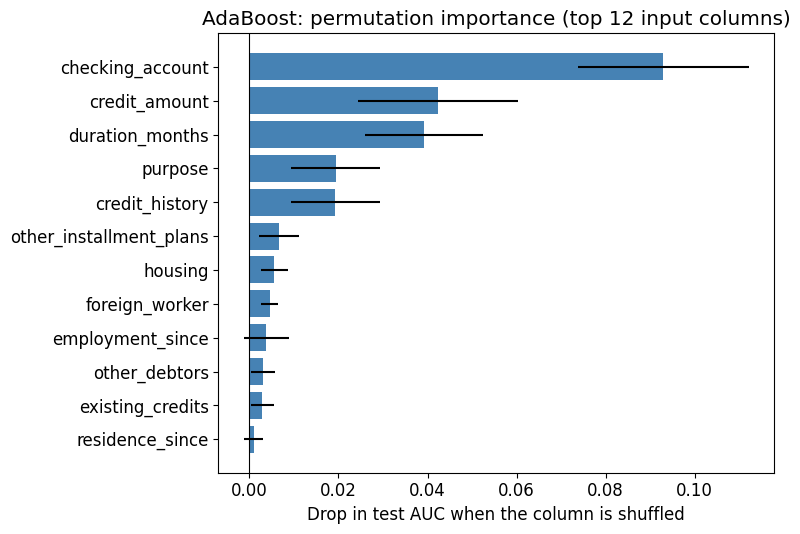

,feature,auc_drop_mean,auc_drop_std
0,checking_account,0.092952,0.019235
1,credit_amount,0.042452,0.017966
2,duration_months,0.039173,0.013205
3,purpose,0.019369,0.009980
4,credit_history,0.019220,0.009994
5,other_installment_plans,0.006554,0.004484
6,housing,0.005589,0.003000
7,foreign_worker,0.004536,0.001839
8,employment_since,0.003792,0.005088
9,other_debtors,0.003071,0.002668


In [10]:
# Columns the pipeline does not use get exactly zero importance and are dropped below
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_test.columns, "auc_drop_mean": pi.importances_mean,
                     "auc_drop_std": pi.importances_std})
       .query("auc_drop_mean != 0 or auc_drop_std != 0")
       .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
imp.to_csv(OUT / "results/adaboost_permutation_importance.csv", index=False)

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_std"], color="steelblue")
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Drop in test AUC when the column is shuffled")
plt.title("AdaBoost: permutation importance (top 12 input columns)")
plt.tight_layout()
plt.savefig(OUT / "results/adaboost_importance.png", dpi=200)
plt.show()
imp.head(12)

**Remark.** `checking_account` again dominates (AUC drop 0.09). It is followed by `credit_amount`, `duration_months`,
`purpose` and `credit_history`, the same core drivers as the random forest, with `purpose` ranked higher.
Below the top five the drops are within noise.

## Part 6: Save model, probabilities and metrics

In [11]:
joblib.dump(best, OUT / "models/adaboost_best.joblib")

summary = {
    "model": "AdaBoostClassifier (SAMME, decision-tree base)",
    "best_params": {k.replace("classifier__", ""): (v if isinstance(v, (str, int, type(None))) else float(v))
                    for k, v in gs.best_params_.items()},
    "cv_auc_mean": float(gs.best_score_), "cv_auc_std": float(cv_std),
    "cv_train_auc_mean": float(cv_train),
    "test_auc_ci95": ci, "fn_cost": FN_COST,
    "thresholds": {"default": 0.5, "f1_opt": t_f1, "cost_opt": t_cost},
    "results": {r["name"]: metrics_only(r) for r in (res_default, res_05, res_f1, res_cost)},
}
(OUT / "results/adaboost_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT)

Saved to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs
